# Introducere în Învățarea Automată

și exerciții pentru setul de instrumente (Toolkit)

# Ce este Învățarea Automată (Machine Learning)?

Învățarea automată le permite calculatoarelor să învețe și să deducă informații din date.





# Obiective de învățare

- Demonstrarea algoritmilor de învățare supervizată
- Explicarea unor concepte cheie precum sub- și supra-antrenarea (under- și over-fitting), regularizarea și validarea încrucișată
- Clasificarea tipului de problemă de rezolvat, alegerea algoritmului potrivit, ajustarea parametrilor și validarea unui model
- Aplicarea extensiei Intel® pentru Scikit-learn* pentru a valorifica capabilitățile de calcul ale hardware-ului


# Prezentare generală a cursului

### Subiectele incluse:
- Introducere și analiză exploratorie (Săptămâna 1)
- Învățare automată supervizată (Săptămânile 2 – 10)
- Învățare automată nesupervizată (Săptămânile 11 – 12)

### Cerințe preliminare:
- Programare în Python
- Calcul diferențial și integral (Calculus)
- Algebră liniară
- Statistică

### Setul nostru de instrumente: Intel® oneAPI AI Analytics Toolkit (AI Kit)
- Extensia Intel® pentru Scikit-learn*

## Introducere
Vom folosi setul de date iris pentru acest tutorial. Acesta este un set de date binecunoscut care conține specii de iris și măsurători ale sepalelelor și petalelor. Datele pe care le vom folosi se află într-un fișier numit `Iris_Data.csv` găsit în directorul [data](../../data)."

In [1]:
from __future__ import print_function
import os
data_path = [ 'datasets']

# Intel® oneAPI Toolkits Installation
The [following documents](https://software.intel.com/content/www/us/en/develop/articles/installation-guide-for-intel-oneapi-toolkits.html) provide detailed instructions on how to get and install Intel® oneAPI packages using different installer modes and package managers:

- [Intel® oneAPI Toolkits Installation Guide for Linux* OS](https://software.intel.com/content/www/us/en/develop/documentation/installation-guide-for-intel-oneapi-toolkits-linux/top.html)
- [Intel® oneAPI Toolkits Installation Guide for Windows*](https://software.intel.com/content/www/us/en/develop/documentation/installation-guide-for-intel-oneapi-toolkits-windows/top.html)
- [Intel® oneAPI Toolkits Installation Guide for macOS*](https://software.intel.com/content/www/us/en/develop/documentation/installation-guide-for-intel-oneapi-toolkits-macos/top.html)



# scikit-learn*

Framework-urile oferă structura pe care o folosesc oamenii de știință a datelor (Data Scientists) pentru a scrie cod. Framework-urile sunt mai mult decât simple biblioteci, deoarece, pe lângă codul apelabil, influențează modul în care este scris codul.

O virtute principală a utilizării unui framework optimizat este că codul rulează mai repede. Codul care rulează mai repede este în general mai convenabil, dar când începem să analizăm știința datelor aplicată și modelele de IA, putem vedea beneficii și mai materiale. Aici veți vedea cum optimizarea, în special optimizarea hiperparametrilor, poate aduce beneficii care depășesc simpla viteză.

Aceste exerciții vor demonstra cum să aplicați **extensia Intel® pentru Scikit-learn*,** o modalitate simplă de a accelera aplicația voastră Scikit-learn. Această accelerare este obținută prin utilizarea bibliotecii Intel® oneAPI Data Analytics Library (oneDAL). „Patching-ul” este termenul utilizat pentru extinderea scikit-learn cu optimizări Intel și o face un cadru de învățare automată foarte potrivit pentru a aborda probleme din viața reală.
        
Pentru a obține versiuni optimizate ale multor algoritmi Scikit-learn folosind o abordare de tip patch() care constă în adăugarea acestor linii de cod după importarea sklearn:

- **from sklearnex import patch_sklearn**
- **patch_sklearn()**


## Întrebarea 1
Încărcați datele din fișier folosind tehnicile învățate astăzi. Examinați-le.
Determinați următoarele:

- Numărul de puncte de date (rânduri). (*Indiciu:* verificați atributul `.shape` al dataframe-ului.)

- Numele coloanelor. (*Indiciu:* verificați atributul `.columns` al dataframe-ului.)

- Tipurile de date pentru fiecare coloană. (*Indiciu:* verificați atributul `.dtypes` al dataframe-ului.)

In [2]:

import numpy as np
import pandas as pd

filepath = '/Users/mac007/workfiles/master_usm/ml/datasets/dataset_iris.csv'
data = pd.read_csv(filepath)
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
# Number of rows
print(data.shape[0])

# Column names
print(data.columns.tolist())

# Data types
print(data.dtypes)

150
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object


## Întrebarea 2

Examinați numele speciilor și observați că toate încep cu „Iris-”. Eliminați această porțiune din nume, astfel încât numele speciei să fie mai scurt.

*Indiciu:* există mai multe modalități de a face acest lucru, dar puteți folosi fie [metodele de procesare a șirurilor de caractere (string)](http://pandas.pydata.org/pandas-docs/stable/text.html), fie [metoda apply](http://pandas.pydata.org/pandas-docs/stable/generated/pandas.Series.apply.html).

In [4]:
# The str method maps the following function to each entry as a string
data['species'] = data.species.str.replace('Iris-', '')
# alternatively
# data['species'] = data.species.apply(lambda r: r.replace('Iris-', ''))

data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Întrebarea 3\

* Numărul de exemplare din fiecare specie. (*Indiciu:* verificați metoda `.value_counts` pentru serii.)
* Media, mediana, quantilele și intervalele (max-min) pentru fiecare măsurătoare de petală și sepală.
*Indiciu:* pentru ultima întrebare, metoda `.describe` include mediana, dar nu se numește mediană, ci cuantila de *50%*. Totuși, `.describe` nu include intervalul (range), iar pentru a-l obține va trebui să creați o nouă intrare în tabelul `.describe`, care să fie `max - min`.

In [5]:
# One way to count each species
data.species.value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [6]:
# Select just the rows desired from the 'describe' method and add in the 'median'
stats_df = data.describe()
stats_df = data.describe()
stats_df.loc['range'] = stats_df.loc['max'] - stats_df.loc['min']

out_fields = ['mean','25%','50%','75%', 'range']
stats_df = stats_df.loc[out_fields]
stats_df.rename({'50%': 'median'}, inplace=True)
stats_df

,sepal_length,sepal_width,petal_length,petal_width
mean,5.843333,3.054,3.758667,1.198667
25%,5.100000,2.800,1.600000,0.300000
median,5.800000,3.000,4.350000,1.300000
75%,6.400000,3.300,5.100000,1.800000
range,3.600000,2.400,5.900000,2.400000


## Întrebarea 4

Calculați următoarele **pentru fiecare specie** într-un dataframe separat:
* Media fiecărei măsurători (sepal_length, sepal_width, petal_length și petal_width).
* Mediana fiecăreia dintre aceste măsurători.
*Indiciu:* poate doriți să utilizați metoda [`groupby` din Pandas](http://pandas.pydata.org/pandas-docs/stable/generated/pandas.DataFrame.groupby.html) pentru a grupa după specie înainte de a calcula statistica.
    
Dacă le terminați pe ambele, încercați să calculați ambele statistici (medie și mediană) într-un singur tabel (adică printr-un singur apel groupby). Consultați secțiunea din documentația Pandas referitoare la [aplicarea mai multor funcții simultan](http://pandas.pydata.org/pandas-docs/stable/groupby.html#applying-multiple-functions-at-once) pentru un indiciu.

In [7]:
# The mean calculation
data.groupby('species').mean()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.418,1.464,0.244
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


In [8]:
# The median calculation
data.groupby('species').median()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.0,3.4,1.50,0.2
versicolor,5.9,2.8,4.35,1.3
virginica,6.5,3.0,5.55,2.0


In [9]:
# applying multiple functions at once - 2 methods

data.groupby('species').agg(['mean', 'median'])  # passing a list of recognized strings
data.groupby('species').agg([np.mean, np.median])  # passing a list of explicit aggregation functions

sepal_length        sepal_width        petal_length         \
                   mean median        mean median         mean median   
species                                                                 
setosa            5.006    5.0       3.418    3.4        1.464   1.50   
versicolor        5.936    5.9       2.770    2.8        4.260   4.35   
virginica         6.588    6.5       2.974    3.0        5.552   5.55   

           petal_width         
                  mean median  
species                        
setosa           0.244    0.2  
versicolor       1.326    1.3  
virginica        2.026    2.0

In [10]:
# If certain fields need to be aggregated differently, we can do:
from pprint import pprint

agg_dict = {field: ['mean', 'median'] for field in data.columns if field != 'species'}
agg_dict['petal_length'] = 'max'
pprint(agg_dict)
data.groupby('species').agg(agg_dict)

{'petal_length': 'max',
 'petal_width': ['mean', 'median'],
 'sepal_length': ['mean', 'median'],
 'sepal_width': ['mean', 'median']}


sepal_length        sepal_width        petal_length petal_width  \
                   mean median        mean median          max        mean   
species                                                                      
setosa            5.006    5.0       3.418    3.4          1.9       0.244   
versicolor        5.936    5.9       2.770    2.8          5.1       1.326   
virginica         6.588    6.5       2.974    3.0          6.9       2.026   

                   
           median  
species            
setosa        0.2  
versicolor    1.3  
virginica     2.0

## Întrebarea 5

Realizați un grafic de tip scatter (dispersie) pentru `sepal_length` în funcție de `sepal_width` folosind Matplotlib. Etichetați axele și dați-i graficului un titlu.

In [11]:
import matplotlib.pyplot as plt
%matplotlib inline

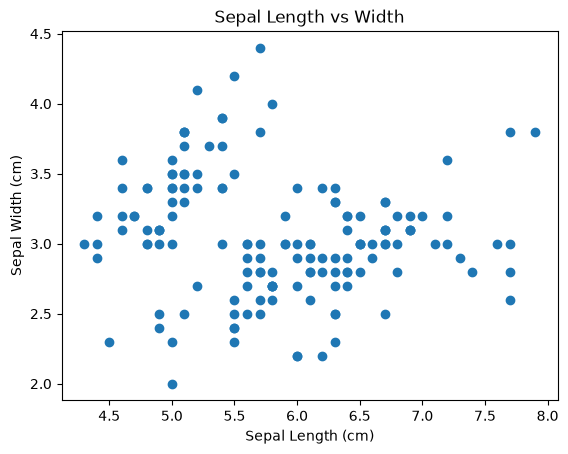

In [12]:
# A simple scatter plot with Matplotlib
ax = plt.axes()

ax.scatter(data.sepal_length, data.sepal_width)

# Label the axes
ax.set(xlabel='Sepal Length (cm)',
       ylabel='Sepal Width (cm)',
       title='Sepal Length vs Width');

## Întrebarea 6

Realizați o histogramă pentru oricare dintre cele patru caracteristici. Etichetați axele și dați-i un titlu adecvat.

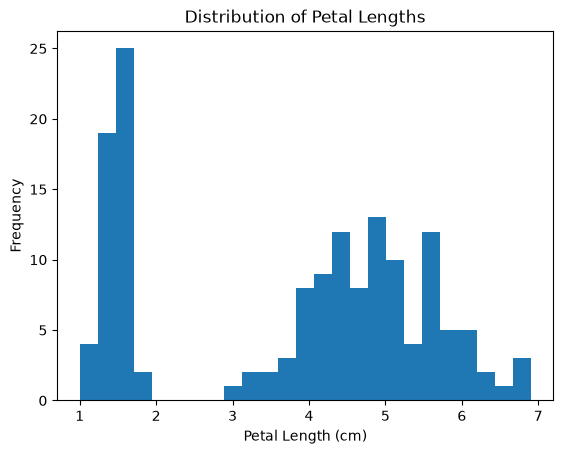

In [13]:
# Using Matplotlib's plotting functionality
ax = plt.axes()
ax.hist(data.petal_length, bins=25);

ax.set(xlabel='Petal Length (cm)',
       ylabel='Frequency',
       title='Distribution of Petal Lengths');

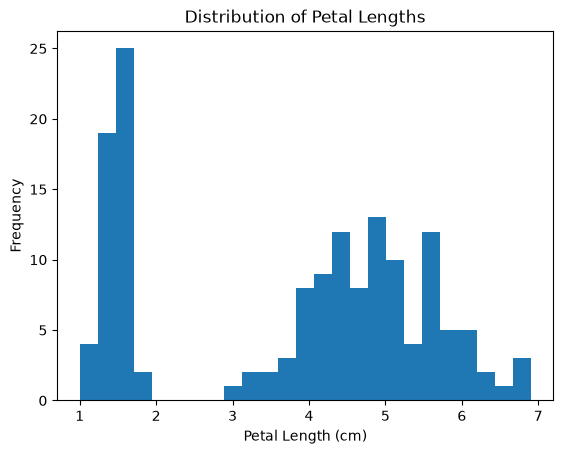

In [14]:
# Alternatively using Pandas plotting functionality
ax = data.petal_length.plot.hist(bins=25)

ax.set(xlabel='Petal Length (cm)',
       ylabel='Frequency',
       title='Distribution of Petal Lengths');

## Întrebarea 7

Acum creați un singur grafic în care să fie suprapuse histogramele pentru fiecare caracteristică (`petal_width`, `petal_length`, `sepal_width`, `sepal_length`). Dacă aveți timp, încercați apoi să creați patru grafice cu histograme separate într-o singură figură, fiecare grafic reprezentând o singură caracteristică.

Pentru câteva sfaturi despre cum să faceți acest lucru folosind metodele de reprezentare grafică din Pandas, consultați [ghidul de vizualizare](http://pandas.pydata.org/pandas-docs/version/0.18.1/visualization.html) pentru Pandas.

In [15]:
try:
    import seaborn as sns

except:
    print('Seaborn must be installed for this course. Execute the following:')
    print('`conda install seaborn`')
    print('from a terminal and restart the kernel.')

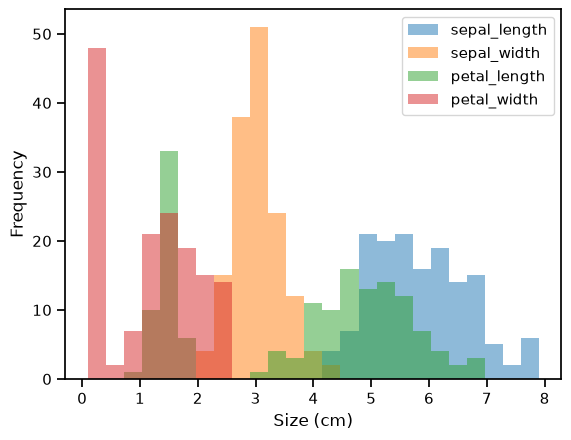

In [16]:
sns.set_context('notebook')

# This uses the `.plot.hist` method
ax = data.plot.hist(bins=25, alpha=0.5)
ax.set_xlabel('Size (cm)');

AttributeError: 'Axes' object has no attribute 'is_last_row'

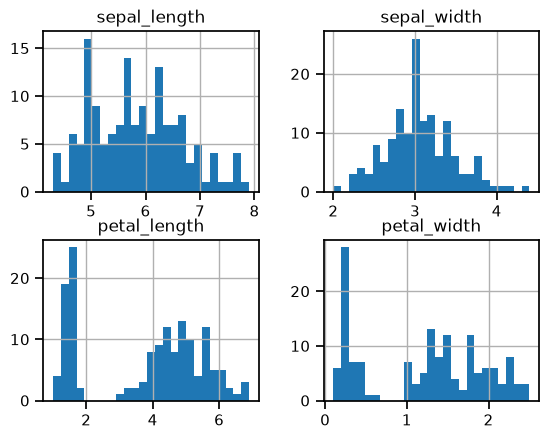

In [18]:
# To create four separate plots, use Pandas `.hist` method
axList = data.hist(bins=25)

# Add some x- and y- labels to first column and last row
for ax in axList.flatten():
    if ax.is_last_row():
        ax.set_xlabel('Size (cm)')

    if ax.is_first_col():
        ax.set_ylabel('Frequency')

## Question 8

Using Pandas, make a boxplot of each petal and sepal measurement. Here is the documentation for [Pandas boxplot method](http://pandas.pydata.org/pandas-docs/version/0.18.1/visualization.html#visualization-box).

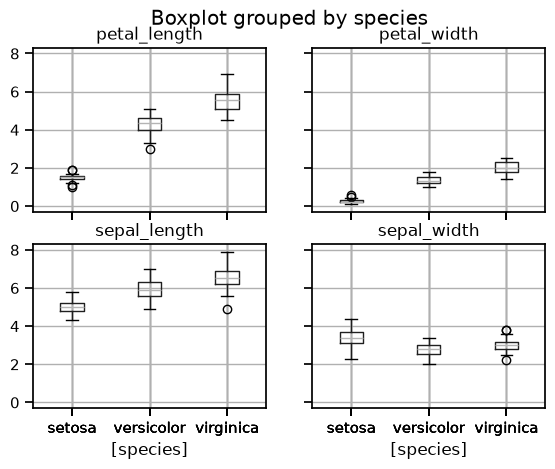

In [19]:
# Pandas plotting functionality is pretty awesome!
# Here we have four separate plots

data.boxplot(by='species');

## Întrebarea 9

Acum creați un singur grafic boxplot în care caracteristicile să fie dispuse pe axa x, iar speciile să fie colorate cu nuanțe diferite.

*Sfat:* vă recomandăm să consultați documentația referitoare la [graficele boxplot din Seaborn](http://seaborn.pydata.org/generated/seaborn.boxplot.html).

De asemenea, rețineți că Seaborn este foarte exigent în ceea ce privește formatul datelor — pentru ca acest grafic să funcționeze, cadrul de date de intrare va trebui modificat astfel încât fiecare rând să conțină un singur punct de date (o specie, un tip de măsurătoare și valoarea măsurătorii). Consultați metoda [stack](http://pandas.pydata.org/pandas-docs/stable/generated/pandas.DataFrame.stack.html) din Pandas ca punct de plecare.

Iată un exemplu de format de date care va funcționa:


|   | species | measurement  | size |
| - | ------- | ------------ | ---- |
| 0	| setosa  | sepal_length | 5.1  |
| 1	| setosa  | sepal_width  | 3.5  |

In [20]:
# First we have to reshape the data so there is
# only a single measurement in each column

plot_data = (data
             .set_index('species')
             .stack()
             .to_frame()
             .reset_index()
             .rename(columns={0:'size', 'level_1':'measurement'})
            )

plot_data.head()

,species,measurement,size
0,setosa,sepal_length,5.1
1,setosa,sepal_width,3.5
2,setosa,petal_length,1.4
3,setosa,petal_width,0.2
4,setosa,sepal_length,4.9


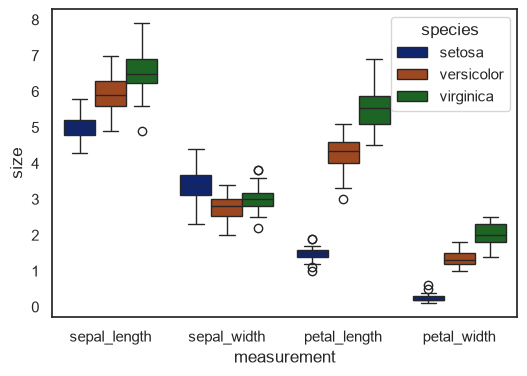

In [21]:
# Now plot the dataframe from above using Seaborn

sns.set_style('white')
sns.set_context('notebook')
sns.set_palette('dark')

f = plt.figure(figsize=(6,4))
sns.boxplot(x='measurement', y='size',
            hue='species', data=plot_data);

## Întrebarea 10

Realizați un [pairplot](http://seaborn.pydata.org/generated/seaborn.pairplot.html) cu Seaborn pentru a analiza corelația dintre fiecare dintre măsurători.

*Sugestie:* acest grafic poate părea complicat, dar, de fapt, este format dintr-o singură linie de cod. Aceasta este puterea Seaborn și a reprezentării grafice adaptate la dataframe! Consultați notele de curs pentru referință.

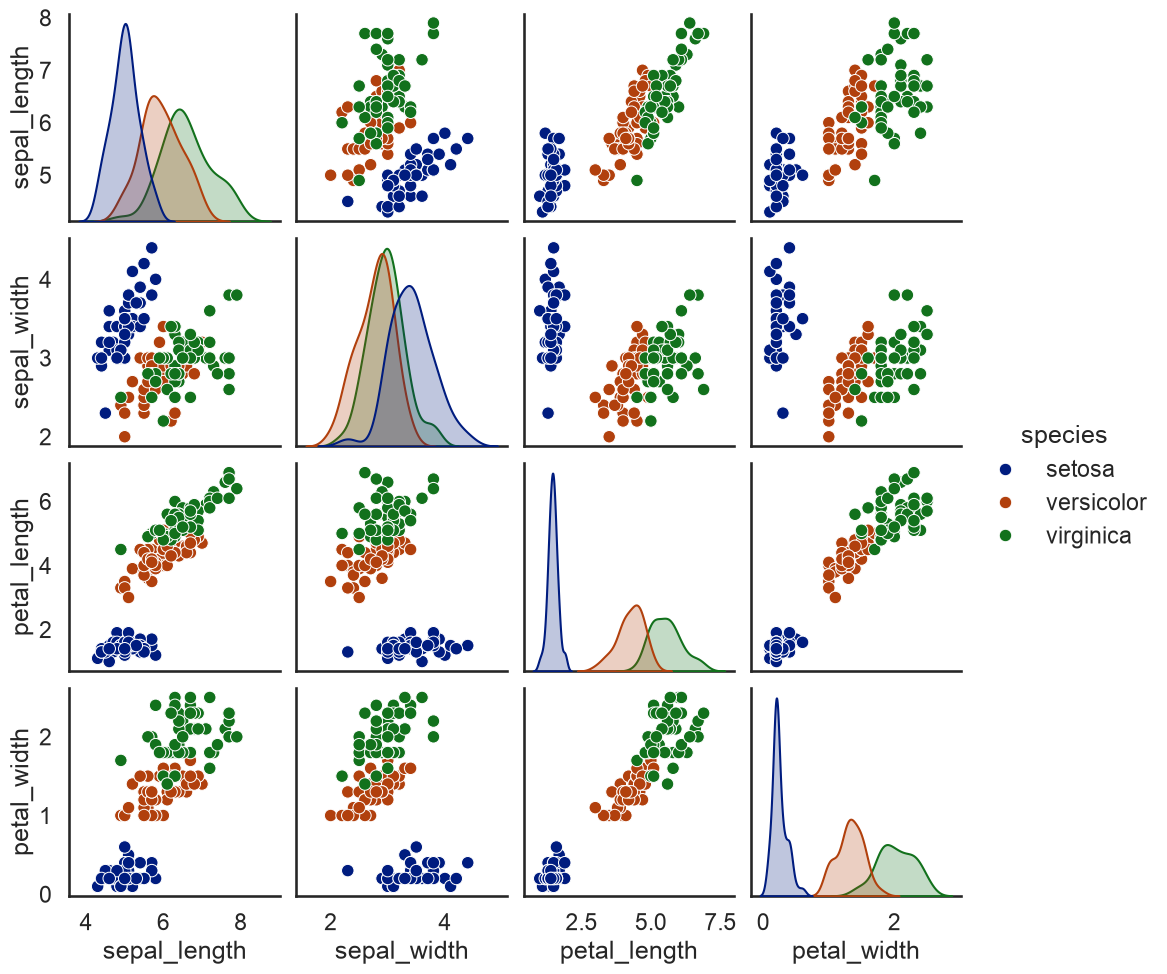

In [22]:
sns.set_context('talk')
sns.pairplot(data, hue='species');